In [1]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

work_dir = Path(
    "/content/drive/MyDrive/ІТХО_ЛР7_Тишко_21"
)

work_dir.mkdir(parents=True, exist_ok=True)

print("Google Drive connected!")

Mounted at /content/drive
Google Drive connected!


In [2]:

text_file = work_dir / "data.txt"

lines = [
    "Laboratory work #7",
    "Variant: 21",
    "Topic: Machine Learning",
    "Platform: Google Colab"
]

with open(text_file, "w", encoding="utf-8") as file:
    file.write("\n".join(lines))

with open(text_file, "r", encoding="utf-8") as file:
    for number, line in enumerate(file, start=1):
        print(f"{number}: {line.strip()}")

1: Laboratory work #7
2: Variant: 21
3: Topic: Machine Learning
4: Platform: Google Colab


In [3]:

import pandas as pd
from sklearn.datasets import load_wine

wine = load_wine()

table = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

table["wine_class"] = [
    wine.target_names[i] for i in wine.target
]

csv_file = work_dir / "wine_data.csv"
table.to_csv(csv_file, index=False)

print("Dataset successfully created!")
print("Rows:", table.shape[0])
print("Columns:", table.shape[1])
print("File:", csv_file)

Dataset successfully created!
Rows: 178
Columns: 14
File: /content/drive/MyDrive/ІТХО_ЛР7_Тишко_21/wine_data.csv


In [4]:

data = pd.read_csv(csv_file)

print("DATASET PREVIEW:")
display(data.sample(5, random_state=21))

print("\nDATASET INFORMATION:")
print(data.info())

print("\nSTATISTICAL SUMMARY:")
display(data.describe().round(2))

print("\nMISSING VALUES:")
print(data.isna().sum())

print("\nWINE CLASSES:")
print(data["wine_class"].value_counts())

DATASET PREVIEW:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,wine_class
13,14.75,1.73,2.39,11.4,91.0,3.10,3.69,0.43,2.81,5.40,1.25,2.73,1150.0,class_0
113,11.41,0.74,2.50,21.0,88.0,2.48,2.01,0.42,1.44,3.08,1.10,2.31,434.0,class_1
21,12.93,3.80,2.65,18.6,102.0,2.41,2.41,0.25,1.98,4.50,1.03,3.52,770.0,class_0
143,13.62,4.95,2.35,20.0,92.0,2.00,0.80,0.47,1.02,4.40,0.91,2.05,550.0,class_2
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,class_2



DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00



MISSING VALUES:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
wine_class                      0
dtype: int64

WINE CLASSES:
wine_class
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


In [5]:

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

features = data.drop(columns=["wine_class"])
labels = data["wine_class"]

X_train, X_test, y_train, y_test = train_test_split(
    features,
    labels,
    test_size=0.25,
    random_state=21,
    stratify=labels
)

classifier = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

score = accuracy_score(y_test, y_pred)

print("KNN MODEL TRAINED!")
print(f"Accuracy: {score:.2%}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

KNN MODEL TRAINED!
Accuracy: 93.33%

Classification report:
              precision    recall  f1-score   support

     class_0       0.94      1.00      0.97        15
     class_1       1.00      0.83      0.91        18
     class_2       0.86      1.00      0.92        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45



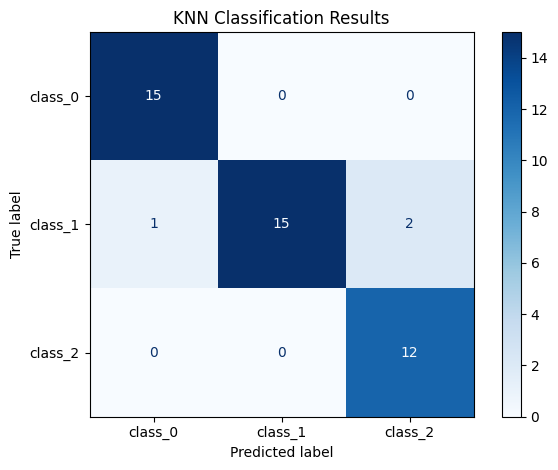

In [6]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)

plt.title("KNN Classification Results")
plt.tight_layout()
plt.show()

In [7]:
examples = X_test.head(5)

predicted = classifier.predict(examples)
expected = y_test.head(5).to_numpy()

comparison = pd.DataFrame({
    "Actual class": expected,
    "Predicted class": predicted,
    "Correct": expected == predicted
})

print("PREDICTION RESULTS:")
display(comparison)

PREDICTION RESULTS:


,Actual class,Predicted class,Correct
0,class_2,class_2,True
1,class_0,class_0,True
2,class_1,class_1,True
3,class_0,class_0,True
4,class_2,class_2,True


In [8]:

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

wine = load_wine()

X_train, X_test, y_train, y_test = train_test_split(
    wine.data,
    wine.target,
    test_size=0.25,
    random_state=21,
    stratify=wine.target
)

network = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(24, 12),
        activation="relu",
        solver="lbfgs",
        max_iter=1500,
        random_state=21
    ))
])

network.fit(X_train, y_train)

predictions = network.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("NEURAL NETWORK TRAINING COMPLETED")
print(f"Accuracy: {accuracy:.2%}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nSample predictions:")
for i in range(5):
    actual = wine.target_names[y_test[i]]
    predicted = wine.target_names[predictions[i]]
    print(f"Actual: {actual} | Predicted: {predicted}")

NEURAL NETWORK TRAINING COMPLETED
Accuracy: 93.33%

Confusion matrix:
[[15  0  0]
 [ 0 17  1]
 [ 0  2 10]]

Sample predictions:
Actual: class_2 | Predicted: class_2
Actual: class_0 | Predicted: class_0
Actual: class_1 | Predicted: class_1
Actual: class_0 | Predicted: class_0
Actual: class_2 | Predicted: class_1
